<a href="https://colab.research.google.com/github/Betty-jyw/MMA3001-Occupancy-Prediction/blob/main/03_model_development.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 - Model Development and Evaluation

## Objective

The purpose of this notebook is to develop and evaluate machine-learning models for predicting building space occupancy 30 minutes into the future.

The following methods will be implemented and compared:

- Persistence Baseline
- Logistic Regression
- Random Forest

The dataset will be split chronologically into training and testing sets to evaluate model performance on later observations.

Model performance will be assessed using accuracy, precision, recall, F1-score, and confusion matrices.

In [1]:
import pandas as pd
import numpy as np

from google.colab import drive

# Mount Google Drive to access the processed dataset
drive.mount("/content/drive")

# Path to the engineered occupancy dataset
file_path = (
    "/content/drive/MyDrive/MMA3001_Project/"
    "data/processed/occupancy_features.csv"
)

# Load the dataset and parse timestamps
data = pd.read_csv(
    file_path,
    parse_dates=["collecteddate"]
)

# Set timestamps as the index and sort chronologically
data = data.set_index("collecteddate")
data = data.sort_index()

# Verify the dataset
print("Dataset shape:", data.shape)

print("\nColumns:")
print(data.columns.tolist())

print("\nTime range:")
print("Start:", data.index.min())
print("End:", data.index.max())

data.head()

Mounted at /content/drive
Dataset shape: (107059, 11)

Columns:
['current_occupancy', 'target_30min', 'lag_5min', 'lag_10min', 'lag_15min', 'lag_30min', 'hour', 'day_of_week', 'recent_occupancy_rate', 'lag_20min', 'lag_25min']

Time range:
Start: 2023-11-23 21:20:00+00:00
End: 2026-04-22 12:30:00+00:00


,current_occupancy,target_30min,lag_5min,lag_10min,lag_15min,lag_30min,hour,day_of_week,recent_occupancy_rate,lag_20min,lag_25min
collecteddate,,,,,,,,,,,
2023-11-23 21:20:00+00:00,0.0,1.0,0.0,0.0,0.0,0.0,21,3,0.000000,0.0,0.0
2023-11-23 21:25:00+00:00,1.0,1.0,0.0,0.0,0.0,0.0,21,3,0.142857,0.0,0.0
2023-11-23 21:30:00+00:00,1.0,0.0,1.0,0.0,0.0,0.0,21,3,0.285714,0.0,0.0
2023-11-23 21:35:00+00:00,0.0,0.0,1.0,1.0,0.0,0.0,21,3,0.285714,0.0,0.0
2023-11-23 21:40:00+00:00,0.0,0.0,0.0,1.0,1.0,0.0,21,3,0.285714,0.0,0.0


In [41]:
# Convert UTC timestamps to Melbourne local time
local_time = data.index.tz_convert("Australia/Melbourne")

# Update time-based features
data["hour"] = local_time.hour
data["day_of_week"] = local_time.dayofweek

# Verify corrected features
print("Corrected time features:")
print(data[["hour", "day_of_week"]].head())

print("\nDataset shape:", data.shape)

Corrected time features:
                           hour  day_of_week
collecteddate                               
2023-11-23 21:20:00+00:00     8            4
2023-11-23 21:25:00+00:00     8            4
2023-11-23 21:30:00+00:00     8            4
2023-11-23 21:35:00+00:00     8            4
2023-11-23 21:40:00+00:00     8            4

Dataset shape: (107059, 11)


## Chronological Train-Test Split

The dataset is divided chronologically into 80% training data and 20% testing data.

Earlier observations are used for model training, while later observations are reserved for testing.

This approach preserves the temporal order of the occupancy data and provides a more realistic evaluation of future occupancy prediction.

In [2]:
# Split the dataset chronologically into training and testing sets
split_index = int(len(data) * 0.8)

train_data = data.iloc[:split_index].copy()
test_data = data.iloc[split_index:].copy()

# Display sample counts
print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

# Display time periods
print("\nTraining period:")
print(train_data.index.min(), "to", train_data.index.max())

print("\nTesting period:")
print(test_data.index.min(), "to", test_data.index.max())

Training samples: 85647
Testing samples: 21412

Training period:
2023-11-23 21:20:00+00:00 to 2025-09-12 06:00:00+00:00

Testing period:
2025-09-12 06:05:00+00:00 to 2026-04-22 12:30:00+00:00


## Persistence Baseline

A persistence baseline is used as a simple benchmark for 30-minute-ahead occupancy prediction.

The baseline assumes that the occupancy state 30 minutes into the future will be the same as the current occupancy state.

The baseline predictions are evaluated on the test dataset using accuracy, precision, recall, F1-score and a confusion matrix.

In [3]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# True occupancy states 30 minutes into the future
y_test = test_data["target_30min"].astype(int)

# Persistence baseline: future occupancy equals current occupancy
baseline_pred = test_data["current_occupancy"].astype(int)

# Calculate classification metrics
baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_precision = precision_score(y_test, baseline_pred)
baseline_recall = recall_score(y_test, baseline_pred)
baseline_f1 = f1_score(y_test, baseline_pred)

# Display evaluation results
print("Persistence Baseline Results")
print("----------------------------")
print(f"Accuracy:  {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"F1-score:  {baseline_f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, baseline_pred))

Persistence Baseline Results
----------------------------
Accuracy:  0.6740
Precision: 0.7511
Recall:    0.7634
F1-score:  0.7572

Confusion Matrix:
[[ 3544  3607]
 [ 3374 10887]]


## Logistic Regression

Logistic Regression is used as the first machine-learning model for 30-minute-ahead occupancy prediction.

The model uses current occupancy, historical occupancy states, recent occupancy patterns and time-based features to predict future occupancy.

The same chronological training and testing sets are used to ensure a fair comparison with the persistence baseline.

In [4]:
# Select the input features
feature_columns = [
    "current_occupancy",
    "lag_5min",
    "lag_10min",
    "lag_15min",
    "lag_20min",
    "lag_25min",
    "lag_30min",
    "hour",
    "day_of_week",
    "recent_occupancy_rate"
]


def prepare_model_data(train_data, test_data, feature_columns, target_column):
    """
    Prepare training and testing data for occupancy prediction.

    Separate input features and prediction targets from chronologically
    divided datasets while preserving their temporal order.

    Parameters
    ----------
    train_data : pandas.DataFrame
        Earlier observations used for model training.
    test_data : pandas.DataFrame
        Later observations reserved for model evaluation.
    feature_columns : list of str
        Names of the input features.
    target_column : str
        Name of the 30-minute-ahead prediction target.

    Returns
    -------
    X_train : pandas.DataFrame
        Training input features.
    y_train : pandas.Series
        Training target values.
    X_test : pandas.DataFrame
        Testing input features.
    y_test : pandas.Series
        Testing target values.
    """
    X_train = train_data[feature_columns]
    y_train = train_data[target_column].astype(int)

    X_test = test_data[feature_columns]
    y_test = test_data[target_column].astype(int)

    return X_train, y_train, X_test, y_test


# Prepare model inputs and targets
X_train, y_train, X_test, y_test = prepare_model_data(
    train_data,
    test_data,
    feature_columns,
    "target_30min"
)

# Verify dataset dimensions and target distributions
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

X_train shape: (85647, 10)
X_test shape: (21412, 10)

Training target distribution:
target_30min
1    0.671641
0    0.328359
Name: proportion, dtype: float64

Testing target distribution:
target_30min
1    0.666028
0    0.333972
Name: proportion, dtype: float64


### Logistic Regression Model Training

A Logistic Regression classifier is trained using the engineered occupancy features.

The model learns the relationship between historical occupancy patterns and the occupancy state 30 minutes into the future.

Predictions are generated on the chronologically separated test dataset to evaluate the model's ability to generalise to later observations.

In [5]:
from sklearn.linear_model import LogisticRegression

# Initialise the Logistic Regression classifier
logistic_model = LogisticRegression(
    max_iter=1000
)

# Train the model on historical observations
logistic_model.fit(X_train, y_train)

# Generate predictions for the testing dataset
logistic_pred = logistic_model.predict(X_test)

# Verify successful training and prediction
print("Logistic Regression training completed.")
print("Number of test predictions:", len(logistic_pred))

Logistic Regression training completed.
Number of test predictions: 21412


### Model Evaluation

The Logistic Regression model is evaluated using the chronologically separated test dataset.

Accuracy, precision, recall, F1-score and the confusion matrix are used to assess classification performance.

The same evaluation function will also be applied to Random Forest to ensure consistent model comparison.

In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


def evaluate_model(y_true, y_pred, model_name):
    """
    Evaluate the performance of a binary occupancy prediction model.

    Compare predicted occupancy states with the actual 30-minute-ahead
    occupancy states using standard classification metrics.

    Parameters
    ----------
    y_true : array-like
        Actual occupancy states in the evaluation dataset.
    y_pred : array-like
        Occupancy states predicted by the model.
    model_name : str
        Name of the model being evaluated.

    Returns
    -------
    dict
        Dictionary containing accuracy, precision, recall and F1-score.
    """
    results = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred)
    }

    print(model_name)
    print("-" * len(model_name))

    for metric, value in results.items():
        print(f"{metric}: {value:.4f}")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

    return results


# Evaluate Logistic Regression on the test dataset
logistic_results = evaluate_model(
    y_test,
    logistic_pred,
    "Logistic Regression Results"
)

Logistic Regression Results
---------------------------
Accuracy: 0.7106
Precision: 0.7418
Recall: 0.8675
F1-score: 0.7997

Confusion Matrix:
[[ 2844  4307]
 [ 1889 12372]]


## Random Forest

Random Forest is used as a second machine-learning model to investigate whether nonlinear relationships between occupancy features can improve prediction performance.

The model is trained using the same training dataset as Logistic Regression and evaluated on the same testing dataset.

Training time is also recorded to support the comparison of computational performance.

In [7]:
from sklearn.ensemble import RandomForestClassifier
import time

# Initialise the Random Forest classifier
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Record the start time
start_time = time.perf_counter()

# Train the model using historical occupancy features
random_forest_model.fit(X_train, y_train)

# Calculate training time
training_time = time.perf_counter() - start_time

# Generate predictions on the testing dataset
random_forest_pred = random_forest_model.predict(X_test)

# Display training information
print("Random Forest training completed.")
print("Number of test predictions:", len(random_forest_pred))
print(f"Training time: {training_time:.2f} seconds")

Random Forest training completed.
Number of test predictions: 21412
Training time: 10.13 seconds


### Random Forest Model Evaluation

The Random Forest model is evaluated using the same chronological test dataset as Logistic Regression.

Classification metrics are calculated using the shared evaluation function to ensure a consistent and fair comparison between models.

In [8]:
# Evaluate Random Forest on the test dataset
random_forest_results = evaluate_model(
    y_test,
    random_forest_pred,
    "Random Forest Results"
)

Random Forest Results
---------------------
Accuracy: 0.6884
Precision: 0.7346
Recall: 0.8330
F1-score: 0.7807

Confusion Matrix:
[[ 2860  4291]
 [ 2382 11879]]


## Training and Testing Performance

To investigate potential overfitting and model generalisation, the performance of Logistic Regression and Random Forest is compared between the training and testing datasets.

A large difference between training and testing performance may indicate overfitting or limited generalisation to later observations.

In [9]:
# Generate predictions on the training dataset
logistic_train_pred = logistic_model.predict(X_train)
random_forest_train_pred = random_forest_model.predict(X_train)

# Evaluate Logistic Regression training performance
logistic_train_results = evaluate_model(
    y_train,
    logistic_train_pred,
    "Logistic Regression Training Results"
)

print("\n")

# Evaluate Random Forest training performance
random_forest_train_results = evaluate_model(
    y_train,
    random_forest_train_pred,
    "Random Forest Training Results"
)

Logistic Regression Training Results
------------------------------------
Accuracy: 0.7222
Precision: 0.7563
Recall: 0.8650
F1-score: 0.8070

Confusion Matrix:
[[12091 16032]
 [ 7765 49759]]


Random Forest Training Results
------------------------------
Accuracy: 0.7992
Precision: 0.8212
Recall: 0.8963
F1-score: 0.8571

Confusion Matrix:
[[16896 11227]
 [ 5967 51557]]


## Model Performance Comparison

The three prediction methods are compared using the same chronological test dataset.

Accuracy, precision, recall and F1-score are used to assess their predictive performance.

The comparison identifies whether machine-learning models provide improvements over the persistence baseline.

In [10]:
# Combine test-set evaluation results into a comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        baseline_accuracy,
        logistic_results["Accuracy"],
        random_forest_results["Accuracy"]
    ],
    "Precision": [
        baseline_precision,
        logistic_results["Precision"],
        random_forest_results["Precision"]
    ],
    "Recall": [
        baseline_recall,
        logistic_results["Recall"],
        random_forest_results["Recall"]
    ],
    "F1-score": [
        baseline_f1,
        logistic_results["F1-score"],
        random_forest_results["F1-score"]
    ]
})

# Round values to four decimal places
model_comparison = model_comparison.round(4)

# Display the comparison table
model_comparison

,Model,Accuracy,Precision,Recall,F1-score
0,Persistence Baseline,0.6740,0.7511,0.7634,0.7572
1,Logistic Regression,0.7106,0.7418,0.8675,0.7997
2,Random Forest,0.6884,0.7346,0.8330,0.7807


### Visual Comparison of Model Performance

A grouped bar chart is used to compare the accuracy, precision, recall and F1-score of the three prediction methods.

The visualisation highlights the differences in predictive performance and supports the selection of the most suitable model for 30-minute-ahead occupancy prediction.

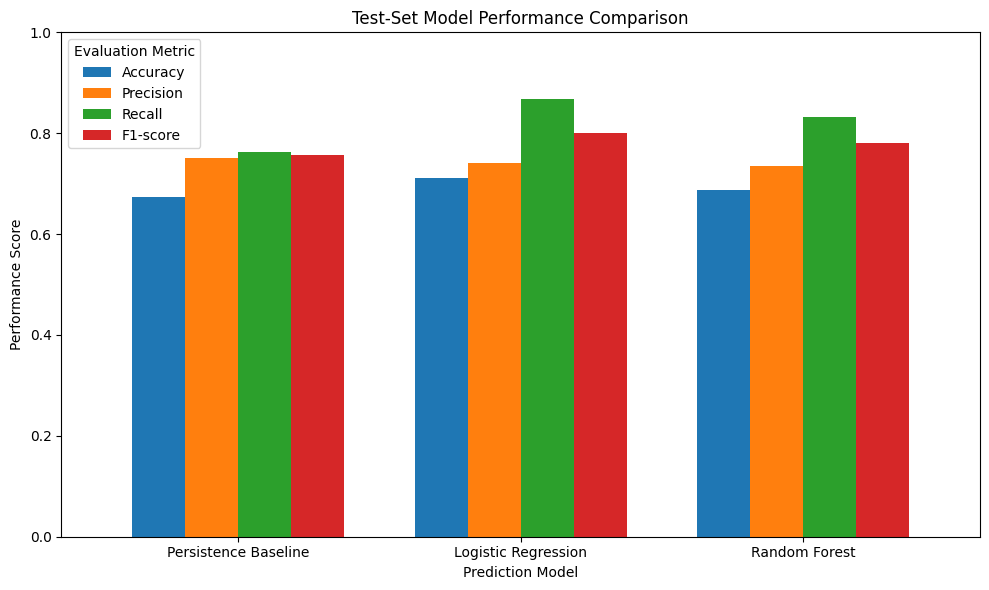

In [11]:
import matplotlib.pyplot as plt

# Select performance metrics for visualisation
plot_data = model_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
]

# Create a grouped bar chart
ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

# Configure chart labels and layout
ax.set_title("Test-Set Model Performance Comparison")
ax.set_xlabel("Prediction Model")
ax.set_ylabel("Performance Score")
ax.set_ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.tight_layout()

# Display the chart
plt.show()

## Feature Importance Analysis

Feature importance is examined to understand which input variables contribute most strongly to the Random Forest model's predictions.

The analysis considers current occupancy, historical occupancy states, recent occupancy patterns and time-based features.

Feature importance scores are used to interpret the model, although they do not establish causal relationships.

In [12]:
# Extract feature importance scores from Random Forest
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display the results
feature_importance

,Feature,Importance
0,hour,0.365752
1,day_of_week,0.188152
2,recent_occupancy_rate,0.187232
3,current_occupancy,0.077477
4,lag_5min,0.047430
5,lag_10min,0.041247
6,lag_15min,0.032280
7,lag_20min,0.025539
8,lag_25min,0.019118
9,lag_30min,0.015774


### Random Forest Feature Importance Visualisation

A horizontal bar chart is used to visualise the relative importance of the ten input features.

The analysis helps identify which temporal and historical occupancy variables are most influential in the Random Forest model.

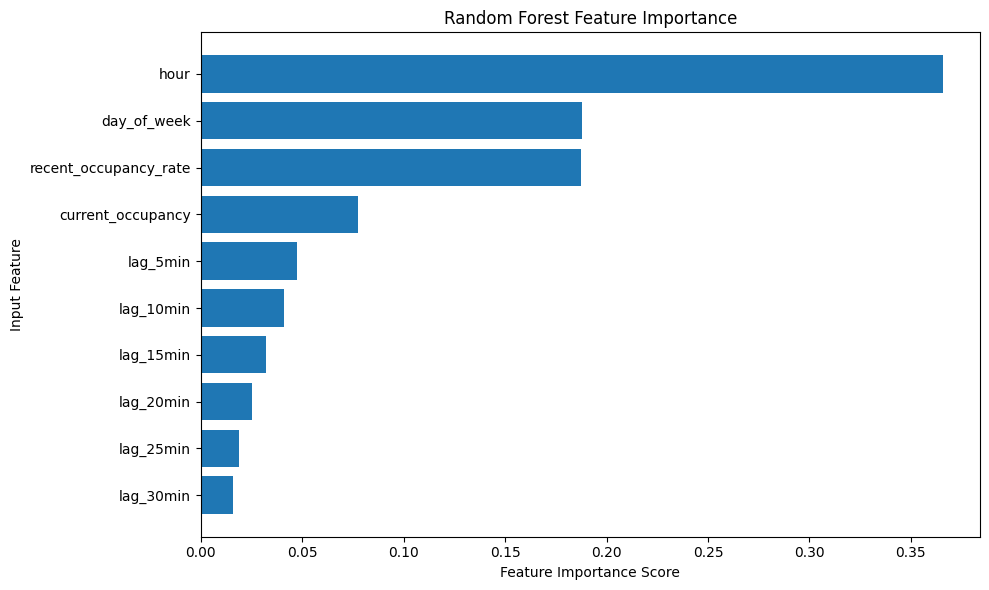

In [13]:
import matplotlib.pyplot as plt

# Sort features for horizontal visualisation
plot_importance = feature_importance.sort_values(
    by="Importance",
    ascending=True
)

# Create the feature importance chart
plt.figure(figsize=(10, 6))

plt.barh(
    plot_importance["Feature"],
    plot_importance["Importance"]
)

# Configure labels and title
plt.xlabel("Feature Importance Score")
plt.ylabel("Input Feature")
plt.title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

## Local Time Validation

The original occupancy timestamps are stored in UTC.

Since the building is located in Melbourne, local time is more appropriate for interpreting daily and weekly occupancy patterns.

The timestamps are converted to the Australia/Melbourne timezone, accounting for daylight saving time.

In [14]:
# Convert UTC timestamps to Melbourne local time
melbourne_time = data.index.tz_convert("Australia/Melbourne")

# Compare UTC and Melbourne time features
time_check = pd.DataFrame({
    "UTC_time": data.index,
    "Melbourne_time": melbourne_time,
    "UTC_hour": data["hour"].to_numpy(),
    "Melbourne_hour": melbourne_time.hour,
    "UTC_day_of_week": data["day_of_week"].to_numpy(),
    "Melbourne_day_of_week": melbourne_time.dayofweek
})

# Display the first five observations
time_check.head()

,UTC_time,Melbourne_time,UTC_hour,Melbourne_hour,UTC_day_of_week,Melbourne_day_of_week
0,2023-11-23 21:20:00+00:00,2023-11-24 08:20:00+11:00,21,8,3,4
1,2023-11-23 21:25:00+00:00,2023-11-24 08:25:00+11:00,21,8,3,4
2,2023-11-23 21:30:00+00:00,2023-11-24 08:30:00+11:00,21,8,3,4
3,2023-11-23 21:35:00+00:00,2023-11-24 08:35:00+11:00,21,8,3,4
4,2023-11-23 21:40:00+00:00,2023-11-24 08:40:00+11:00,21,8,3,4


## Local Time Feature Correction

The original hour and day-of-week features were extracted from UTC timestamps.

To better represent local building usage patterns, these features are recalculated using the Australia/Melbourne timezone.

The original timestamps and occupancy targets remain unchanged. Only the two time-based input features are updated.

### Model Retraining with Corrected Local-Time Features

The training and testing datasets are reconstructed using the corrected Melbourne local-time features.

The original chronological 80/20 split is preserved to maintain consistency with the initial experiments.

All machine-learning models will be retrained to assess the effect of the time-feature correction.

In [17]:
# Recreate the chronological training and testing datasets
split_index = int(len(data) * 0.8)

train_data = data.iloc[:split_index].copy()
test_data = data.iloc[split_index:].copy()

# Prepare features and targets using the existing function
X_train, y_train, X_test, y_test = prepare_model_data(
    train_data,
    test_data,
    feature_columns,
    "target_30min"
)

# Verify the updated datasets
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nCorrected training time features:")
print(X_train[["hour", "day_of_week"]].head())

print("\nCorrected testing time features:")
print(X_test[["hour", "day_of_week"]].head())

# Confirm that the time features match Melbourne local time
local_train_time = X_train.index.tz_convert("Australia/Melbourne")
local_test_time = X_test.index.tz_convert("Australia/Melbourne")

assert (X_train["hour"].to_numpy() == local_train_time.hour).all()
assert (X_test["hour"].to_numpy() == local_test_time.hour).all()
assert (X_train["day_of_week"].to_numpy() == local_train_time.dayofweek).all()
assert (X_test["day_of_week"].to_numpy() == local_test_time.dayofweek).all()

print("\nLocal-time feature validation passed.")

X_train shape: (85647, 10)
X_test shape: (21412, 10)

Corrected training time features:
                           hour  day_of_week
collecteddate                               
2023-11-23 21:20:00+00:00     8            4
2023-11-23 21:25:00+00:00     8            4
2023-11-23 21:30:00+00:00     8            4
2023-11-23 21:35:00+00:00     8            4
2023-11-23 21:40:00+00:00     8            4

Corrected testing time features:
                           hour  day_of_week
collecteddate                               
2025-09-12 06:05:00+00:00    16            4
2025-09-12 06:10:00+00:00    16            4
2025-09-12 06:15:00+00:00    16            4
2025-09-12 06:20:00+00:00    16            4
2025-09-12 06:25:00+00:00    16            4

Local-time feature validation passed.


### Logistic Regression Retraining

The Logistic Regression model is retrained using the corrected Melbourne local-time features.

The chronological train-test split and other occupancy features remain unchanged, allowing the effect of the time-feature correction to be examined.

In [18]:
from sklearn.linear_model import LogisticRegression
import time

# Initialise the Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000
)

# Record the training start time
start_time = time.perf_counter()

# Retrain using corrected local-time features
logistic_model.fit(X_train, y_train)

# Calculate training time
logistic_training_time = time.perf_counter() - start_time

# Generate updated test predictions
logistic_pred = logistic_model.predict(X_test)

# Evaluate the retrained model
logistic_results = evaluate_model(
    y_test,
    logistic_pred,
    "Logistic Regression (Melbourne Time)"
)

print(f"\nTraining time: {logistic_training_time:.2f} seconds")

Logistic Regression (Melbourne Time)
------------------------------------
Accuracy: 0.7168
Precision: 0.7430
Recall: 0.8788
F1-score: 0.8052

Confusion Matrix:
[[ 2816  4335]
 [ 1728 12533]]

Training time: 0.57 seconds


### Random Forest Retraining with Melbourne Local Time

The Random Forest model is retrained using the corrected Melbourne local-time features.

The model configuration and chronological data split remain unchanged, allowing a consistent comparison with the original Random Forest results and the updated Logistic Regression model.

In [19]:
from sklearn.ensemble import RandomForestClassifier
import time

# Initialise the Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Measure training time
start_time = time.perf_counter()

# Retrain with corrected Melbourne time features
random_forest_model.fit(X_train, y_train)

random_forest_training_time = time.perf_counter() - start_time

# Generate updated test predictions
random_forest_pred = random_forest_model.predict(X_test)

# Evaluate the updated Random Forest model
random_forest_results = evaluate_model(
    y_test,
    random_forest_pred,
    "Random Forest (Melbourne Time)"
)

print(
    f"\nTraining time: {random_forest_training_time:.2f} seconds"
)

Random Forest (Melbourne Time)
------------------------------
Accuracy: 0.6902
Precision: 0.7362
Recall: 0.8334
F1-score: 0.7818

Confusion Matrix:
[[ 2893  4258]
 [ 2376 11885]]

Training time: 5.56 seconds


## Updated Model Performance Comparison

The final model comparison uses the corrected Melbourne local-time features.

All models are evaluated on the same chronological test dataset. The persistence baseline remains unchanged because it does not use time-based features.

The updated results are used to compare predictive accuracy, classification performance and model suitability.

In [20]:
# Update the comparison table with the retrained model results
model_comparison = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        baseline_accuracy,
        logistic_results["Accuracy"],
        random_forest_results["Accuracy"]
    ],
    "Precision": [
        baseline_precision,
        logistic_results["Precision"],
        random_forest_results["Precision"]
    ],
    "Recall": [
        baseline_recall,
        logistic_results["Recall"],
        random_forest_results["Recall"]
    ],
    "F1-score": [
        baseline_f1,
        logistic_results["F1-score"],
        random_forest_results["F1-score"]
    ]
})

# Round performance metrics to four decimal places
model_comparison = model_comparison.round(4)

# Display the updated comparison
model_comparison

,Model,Accuracy,Precision,Recall,F1-score
0,Persistence Baseline,0.6740,0.7511,0.7634,0.7572
1,Logistic Regression,0.7168,0.7430,0.8788,0.8052
2,Random Forest,0.6902,0.7362,0.8334,0.7818


### Updated Model Performance Visualisation

A grouped bar chart compares the test-set performance of the three prediction methods after correcting the time-based features to Melbourne local time.

The visualisation highlights differences in accuracy, precision, recall and F1-score, providing evidence for model selection.

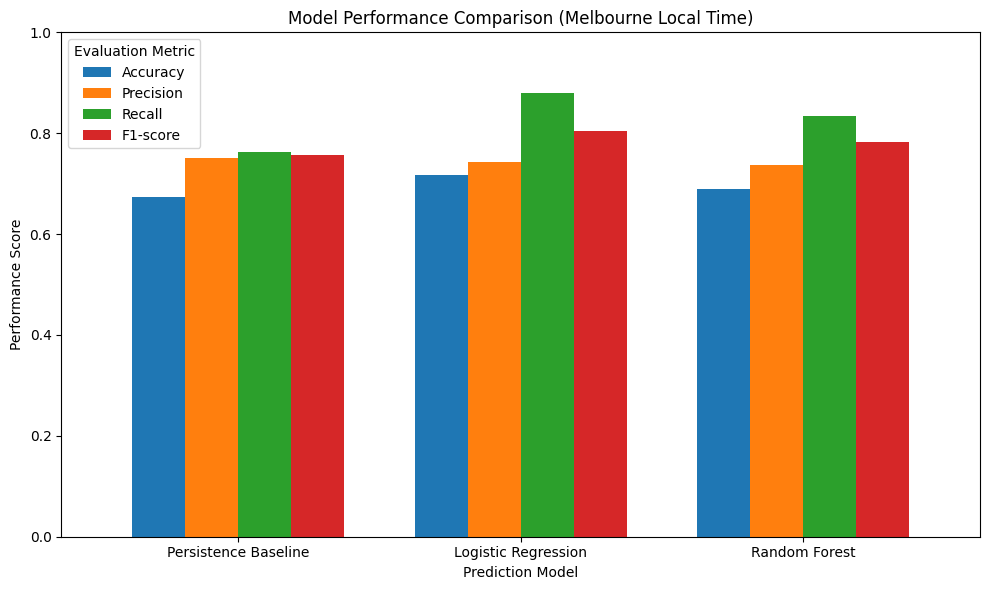

In [21]:
import matplotlib.pyplot as plt

# Select updated evaluation metrics
plot_data = model_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
]

# Create the updated grouped bar chart
ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

# Configure chart appearance
ax.set_title("Model Performance Comparison (Melbourne Local Time)")
ax.set_xlabel("Prediction Model")
ax.set_ylabel("Performance Score")
ax.set_ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.tight_layout()

# Display the updated chart
plt.show()

## Updated Feature Importance Analysis

Feature importance is recalculated using the Random Forest model trained with Melbourne local-time features.

The analysis identifies which input variables contribute most strongly to the updated model's predictions.

The importance scores are based on impurity reduction and should not be interpreted as causal effects.

In [22]:
# Extract feature importance from the updated Random Forest
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

# Sort features by importance in descending order
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display updated importance scores
feature_importance

,Feature,Importance
0,hour,0.381978
1,recent_occupancy_rate,0.183932
2,day_of_week,0.171485
3,current_occupancy,0.076353
4,lag_5min,0.052005
5,lag_10min,0.044495
6,lag_15min,0.031100
7,lag_20min,0.021405
8,lag_25min,0.019617
9,lag_30min,0.017628


### Updated Random Forest Feature Importance Visualisation

A horizontal bar chart presents the feature importance scores of the Random Forest model trained using Melbourne local-time features.

The visualisation highlights the relative contributions of time-based variables and historical occupancy features.

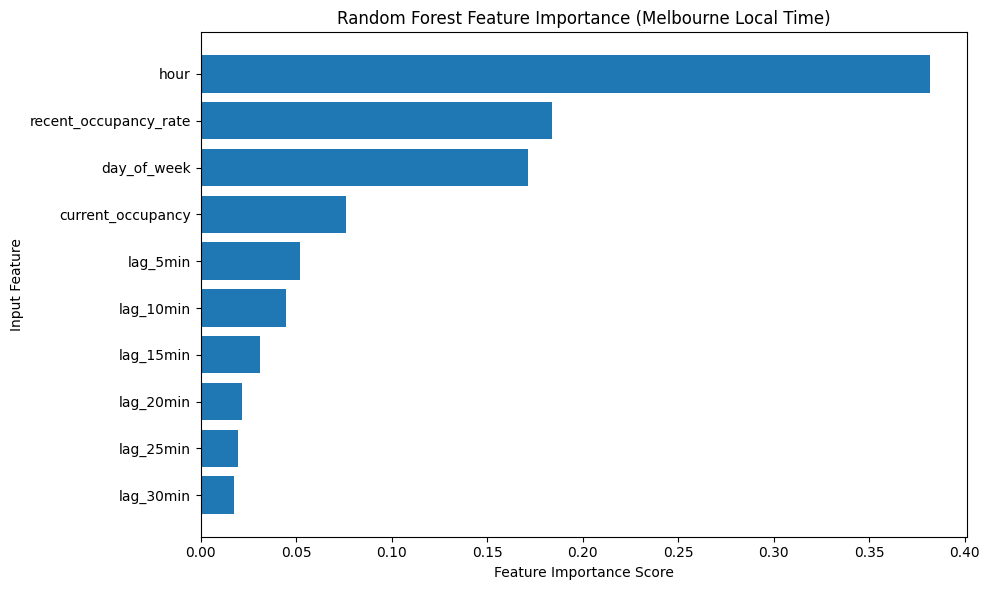

In [23]:
import matplotlib.pyplot as plt

# Sort feature importance scores for horizontal plotting
plot_importance = feature_importance.sort_values(
    by="Importance",
    ascending=True
)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    plot_importance["Feature"],
    plot_importance["Importance"]
)

# Configure chart labels and title
plt.xlabel("Feature Importance Score")
plt.ylabel("Input Feature")
plt.title("Random Forest Feature Importance (Melbourne Local Time)")

plt.tight_layout()
plt.show()

## Model Generalisation Analysis

The training and testing performance of Logistic Regression and Random Forest is compared after correcting the time-based features to Melbourne local time.

Differences between training and testing accuracy and F1-score are examined to identify potential overfitting or limitations in temporal generalisation.

The comparison provides additional evidence for selecting a suitable occupancy prediction model.

In [24]:
# Generate training predictions using the updated models
logistic_train_pred = logistic_model.predict(X_train)
random_forest_train_pred = random_forest_model.predict(X_train)

# Evaluate Logistic Regression training performance
logistic_train_results = evaluate_model(
    y_train,
    logistic_train_pred,
    "Logistic Regression Training Results (Melbourne Time)"
)

print("\n")

# Evaluate Random Forest training performance
random_forest_train_results = evaluate_model(
    y_train,
    random_forest_train_pred,
    "Random Forest Training Results (Melbourne Time)"
)

Logistic Regression Training Results (Melbourne Time)
-----------------------------------------------------
Accuracy: 0.7235
Precision: 0.7567
Recall: 0.8671
F1-score: 0.8082

Confusion Matrix:
[[12084 16039]
 [ 7643 49881]]


Random Forest Training Results (Melbourne Time)
-----------------------------------------------
Accuracy: 0.7984
Precision: 0.8199
Recall: 0.8967
F1-score: 0.8566

Confusion Matrix:
[[16796 11327]
 [ 5943 51581]]


### Training and Testing Performance Comparison

Training and testing accuracy and F1-score are compared to assess the generalisation of the machine-learning models.

The performance gaps are calculated as training performance minus testing performance. Larger positive gaps may indicate overfitting or changes in occupancy patterns between the training and testing periods.

In [25]:
# Compare training and testing performance
generalisation_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Train Accuracy": [
        logistic_train_results["Accuracy"],
        random_forest_train_results["Accuracy"]
    ],
    "Test Accuracy": [
        logistic_results["Accuracy"],
        random_forest_results["Accuracy"]
    ],
    "Train F1": [
        logistic_train_results["F1-score"],
        random_forest_train_results["F1-score"]
    ],
    "Test F1": [
        logistic_results["F1-score"],
        random_forest_results["F1-score"]
    ]
})

# Calculate train-test performance gaps
generalisation_comparison["Accuracy Gap"] = (
    generalisation_comparison["Train Accuracy"]
    - generalisation_comparison["Test Accuracy"]
)

generalisation_comparison["F1 Gap"] = (
    generalisation_comparison["Train F1"]
    - generalisation_comparison["Test F1"]
)

# Display results rounded to four decimal places
generalisation_comparison.round(4)

,Model,Train Accuracy,Test Accuracy,Train F1,Test F1,Accuracy Gap,F1 Gap
0,Logistic Regression,0.7235,0.7168,0.8082,0.8052,0.0067,0.0029
1,Random Forest,0.7984,0.6902,0.8566,0.7818,0.1082,0.0748


## Temporal Validation

To assess the stability of the selected Logistic Regression model, its predictive performance is evaluated separately for each calendar month in the test dataset.

Monthly accuracy and F1-score are calculated to investigate whether model performance varies across different time periods.

This analysis provides additional evidence about temporal generalisation beyond the overall test-set metrics.

In [26]:
# Create a DataFrame containing test predictions and actual values
temporal_results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": logistic_pred
}, index=X_test.index)

# Convert timestamps to Melbourne local time
local_test_index = temporal_results.index.tz_convert(
    "Australia/Melbourne"
)

# Extract calendar months
temporal_results["Month"] = local_test_index.strftime("%Y-%m")

# Calculate performance for each month
monthly_results = []

for month, group in temporal_results.groupby("Month"):
    monthly_results.append({
        "Month": month,
        "Samples": len(group),
        "Accuracy": accuracy_score(
            group["Actual"],
            group["Predicted"]
        ),
        "F1-score": f1_score(
            group["Actual"],
            group["Predicted"],
            zero_division=0
        )
    })

# Convert results into a DataFrame
monthly_performance = pd.DataFrame(monthly_results)

# Display monthly performance
monthly_performance.round(4)

,Month,Samples,Accuracy,F1-score
0,2025-09,1897,0.7364,0.8257
1,2025-10,4044,0.7295,0.8227
2,2025-11,3295,0.6753,0.7375
3,2025-12,2077,0.6370,0.7155
4,2026-01,2045,0.6880,0.7889
5,2026-02,2553,0.6937,0.7928
6,2026-03,3176,0.7802,0.8625
7,2026-04,2325,0.7733,0.8490


### Monthly Occupancy Distribution Analysis

The distribution of actual occupancy states is examined for each month in the test dataset.

This analysis investigates whether changes in the proportion of occupied and unoccupied observations may help explain variations in monthly prediction performance.

Differences in occupancy distribution are considered as potential contributors to temporal performance variation, rather than definitive causes.

In [27]:
# Calculate the proportion of occupied observations per month
monthly_occupancy = (
    temporal_results
    .groupby("Month")["Actual"]
    .agg(
        Samples="count",
        Occupancy_Rate="mean"
    )
    .reset_index()
)

# Calculate the proportion of unoccupied observations
monthly_occupancy["Unoccupied_Rate"] = (
    1 - monthly_occupancy["Occupancy_Rate"]
)

# Combine occupancy distribution with model performance
monthly_analysis = monthly_performance.merge(
    monthly_occupancy[
        ["Month", "Occupancy_Rate", "Unoccupied_Rate"]
    ],
    on="Month"
)

# Display the combined results
monthly_analysis.round(4)

,Month,Samples,Accuracy,F1-score,Occupancy_Rate,Unoccupied_Rate
0,2025-09,1897,0.7364,0.8257,0.6869,0.3131
1,2025-10,4044,0.7295,0.8227,0.6978,0.3022
2,2025-11,3295,0.6753,0.7375,0.5630,0.4370
3,2025-12,2077,0.6370,0.7155,0.5672,0.4328
4,2026-01,2045,0.6880,0.7889,0.6743,0.3257
5,2026-02,2553,0.6937,0.7928,0.6627,0.3373
6,2026-03,3176,0.7802,0.8625,0.7450,0.2550
7,2026-04,2325,0.7733,0.8490,0.7166,0.2834


### Monthly Prediction Bias Analysis

The predicted occupancy rate is compared with the actual occupancy rate for each month in the test dataset.

The difference between predicted and actual occupancy rates is calculated to identify potential systematic overprediction or underprediction of occupied states.

This analysis helps explain variations in model performance across different time periods.

In [28]:
# Calculate actual and predicted occupancy rates by month
monthly_prediction_bias = (
    temporal_results
    .groupby("Month")
    .agg(
        Samples=("Actual", "count"),
        Actual_Occupancy_Rate=("Actual", "mean"),
        Predicted_Occupancy_Rate=("Predicted", "mean")
    )
    .reset_index()
)

# Calculate prediction bias
monthly_prediction_bias["Prediction_Bias"] = (
    monthly_prediction_bias["Predicted_Occupancy_Rate"]
    - monthly_prediction_bias["Actual_Occupancy_Rate"]
)

# Display the results
monthly_prediction_bias.round(4)

,Month,Samples,Actual_Occupancy_Rate,Predicted_Occupancy_Rate,Prediction_Bias
0,2025-09,1897,0.6869,0.8250,0.1381
1,2025-10,4044,0.6978,0.8284,0.1306
2,2025-11,3295,0.5630,0.6741,0.1111
3,2025-12,2077,0.5672,0.7087,0.1416
4,2026-01,2045,0.6743,0.8034,0.1291
5,2026-02,2553,0.6627,0.8155,0.1528
6,2026-03,3176,0.7450,0.8533,0.1083
7,2026-04,2325,0.7166,0.7849,0.0684


## Prediction Threshold Sensitivity Analysis

The sensitivity of Logistic Regression predictions to different classification thresholds is investigated.

Thresholds from 0.3 to 0.7 are evaluated to examine the trade-off between accuracy, precision, recall, F1-score and occupancy prediction bias.

This analysis is exploratory. The test-set results are not used to select or tune the final model threshold.

In [29]:
# Obtain predicted probabilities for the occupied class
occupancy_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Define classification thresholds
thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

threshold_results = []

for threshold in thresholds:
    # Convert probabilities into binary predictions
    predictions = (
        occupancy_probabilities >= threshold
    ).astype(int)

    # Calculate evaluation metrics and prediction bias
    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "Prediction_Bias": (
            predictions.mean() - y_test.mean()
        )
    })

# Create and display the sensitivity table
threshold_comparison = pd.DataFrame(threshold_results)

threshold_comparison.round(4)

,Threshold,Accuracy,Precision,Recall,F1-score,Prediction_Bias
0,0.3,0.6904,0.6878,0.9802,0.8083,0.2832
1,0.4,0.7089,0.7143,0.9380,0.8110,0.2086
2,0.5,0.7168,0.7430,0.8788,0.8052,0.1218
3,0.6,0.7045,0.7689,0.7954,0.7819,0.0230
4,0.7,0.6765,0.8052,0.6784,0.7364,-0.1049


### Classification Threshold Sensitivity Visualisation

The effect of classification thresholds on accuracy, precision, recall, F1-score and prediction bias is visualised.

The analysis illustrates the trade-offs between detecting occupied states and reducing systematic overprediction.

The default threshold of 0.5 is retained for the main model comparison. Alternative thresholds are examined for sensitivity analysis only.

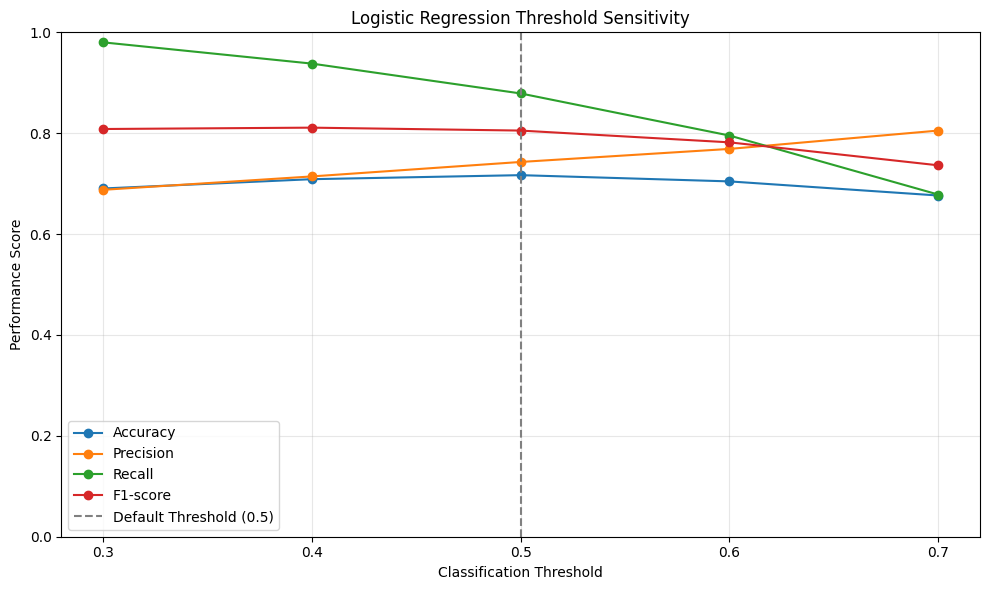

In [30]:
import matplotlib.pyplot as plt

# Create a line chart of classification performance
plt.figure(figsize=(10, 6))

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

for metric in metrics:
    plt.plot(
        threshold_comparison["Threshold"],
        threshold_comparison[metric],
        marker="o",
        label=metric
    )

# Mark the default classification threshold
plt.axvline(
    x=0.5,
    linestyle="--",
    color="gray",
    label="Default Threshold (0.5)"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Performance Score")
plt.title("Logistic Regression Threshold Sensitivity")
plt.ylim(0, 1)
plt.xticks(thresholds)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

## Training-Only Validation

The original training dataset is divided chronologically into a model-fitting subset (80%) and a validation subset (20%).

The validation subset is used for model development and threshold selection without accessing the held-out test dataset.

A 30-minute gap is introduced before the validation period to prevent training labels from overlapping with the validation period.

In [31]:
# Split the original training dataset chronologically
validation_split = int(len(train_data) * 0.8)

fit_data = train_data.iloc[:validation_split].copy()
validation_data = train_data.iloc[validation_split:].copy()

# Remove training samples whose target time reaches
# the validation period
validation_start = validation_data.index.min()

fit_data = fit_data.loc[
    fit_data.index + pd.Timedelta(minutes=30) < validation_start
].copy()

# Prepare input features and targets
X_fit = fit_data[feature_columns]
y_fit = fit_data["target_30min"].astype(int)

X_val = validation_data[feature_columns]
y_val = validation_data["target_30min"].astype(int)

# Display dataset sizes and time ranges
print("Model-fitting samples:", len(X_fit))
print("Validation samples:", len(X_val))

print("\nModel-fitting period:")
print(X_fit.index.min(), "to", X_fit.index.max())

print("\nValidation period:")
print(X_val.index.min(), "to", X_val.index.max())

# Verify chronological separation
assert X_fit.index.max() + pd.Timedelta(minutes=30) < X_val.index.min()

print("\nTemporal separation validation passed.")

Model-fitting samples: 68511
Validation samples: 17130

Model-fitting period:
2023-11-23 21:20:00+00:00 to 2025-04-30 10:50:00+00:00

Validation period:
2025-04-30 11:25:00+00:00 to 2025-09-12 06:00:00+00:00

Temporal separation validation passed.


### Logistic Regression Validation Model

A separate Logistic Regression model is trained using only the model-fitting subset.

The model is then evaluated on the chronologically later validation subset.

This procedure allows model performance and classification thresholds to be investigated without using the held-out test dataset.

In [32]:
from sklearn.linear_model import LogisticRegression

# Initialise a separate model for validation
logistic_val_model = LogisticRegression(
    max_iter=1000
)

# Train using only the model-fitting subset
logistic_val_model.fit(X_fit, y_fit)

# Generate predictions on the validation dataset
logistic_val_pred = logistic_val_model.predict(X_val)

# Evaluate validation performance
logistic_val_results = evaluate_model(
    y_val,
    logistic_val_pred,
    "Logistic Regression Validation Results"
)

print("\nValidation samples:", len(logistic_val_pred))

Logistic Regression Validation Results
--------------------------------------
Accuracy: 0.7441
Precision: 0.7699
Recall: 0.8816
F1-score: 0.8220

Confusion Matrix:
[[ 2628  3024]
 [ 1359 10119]]

Validation samples: 17130


### Validation-Based Threshold Sensitivity Analysis

Classification thresholds are evaluated using the validation dataset rather than the held-out test dataset.

The analysis compares accuracy, precision, recall, F1-score and occupancy prediction bias across different thresholds.

The validation results provide a basis for selecting a classification threshold before final testing.

In [33]:
# Obtain occupied-class probabilities on the validation dataset
validation_probabilities = logistic_val_model.predict_proba(X_val)[:, 1]

# Define candidate classification thresholds
validation_thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

validation_threshold_results = []

for threshold in validation_thresholds:
    # Convert probabilities to binary occupancy predictions
    predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    # Calculate validation metrics
    validation_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "Prediction_Bias": predictions.mean() - y_val.mean()
    })

# Create the validation threshold comparison table
validation_threshold_comparison = pd.DataFrame(
    validation_threshold_results
)

# Display results
validation_threshold_comparison.round(4)

,Threshold,Accuracy,Precision,Recall,F1-score,Prediction_Bias
0,0.3,0.6991,0.6955,0.9799,0.8136,0.2740
1,0.4,0.7270,0.7310,0.9375,0.8215,0.1893
2,0.5,0.7441,0.7699,0.8816,0.8220,0.0972
3,0.6,0.7441,0.8092,0.8087,0.8090,-0.0005
4,0.7,0.7246,0.8507,0.7143,0.7766,-0.1074


### Validation-Based Threshold Selection

The classification threshold is selected using the validation dataset.

A threshold of 0.5 is retained because it achieves the highest validation F1-score among the evaluated candidates while maintaining relatively high recall.

A threshold of 0.6 achieves the same rounded validation accuracy and substantially reduces aggregate occupancy prediction bias, but results in a lower F1-score and recall.

The selected threshold is fixed before final test-set evaluation to avoid tuning on the held-out test data.

In [34]:
# Select the threshold using validation F1-score
best_row = validation_threshold_comparison.loc[
    validation_threshold_comparison["F1-score"].idxmax()
]

selected_threshold = float(best_row["Threshold"])

# Display the selected threshold and its validation metrics
print("Selected threshold:", selected_threshold)
print(f"Validation Accuracy: {best_row['Accuracy']:.4f}")
print(f"Validation F1-score: {best_row['F1-score']:.4f}")
print(f"Validation Recall: {best_row['Recall']:.4f}")
print(f"Validation Prediction Bias: {best_row['Prediction_Bias']:.4f}")

Selected threshold: 0.5
Validation Accuracy: 0.7441
Validation F1-score: 0.8220
Validation Recall: 0.8816
Validation Prediction Bias: 0.0972


## Final Test-Set Temporal Separation

A 30-minute temporal separation is introduced between the training and testing datasets.

Since the prediction target represents occupancy 30 minutes into the future, training samples whose target timestamps overlap with the test period are excluded.

This ensures that model training does not use occupancy labels from the held-out testing period.

In [35]:
# Identify the beginning of the held-out test period
test_start = test_data.index.min()

# Exclude training samples whose prediction targets
# reach into the testing period
final_train_data = train_data.loc[
    train_data.index + pd.Timedelta(minutes=30) < test_start
].copy()

# Prepare the final model training dataset
X_train_final = final_train_data[feature_columns]
y_train_final = final_train_data["target_30min"].astype(int)

# Preserve the original held-out testing dataset
X_test_final = test_data[feature_columns]
y_test_final = test_data["target_30min"].astype(int)

# Display the final sample counts
print("Final training samples:", len(X_train_final))
print("Final testing samples:", len(X_test_final))

print("\nLast training timestamp:")
print(X_train_final.index.max())

print("\nFirst testing timestamp:")
print(X_test_final.index.min())

# Verify that training targets end before testing begins
assert (
    X_train_final.index.max() + pd.Timedelta(minutes=30)
    < X_test_final.index.min()
)

print("\nFinal temporal separation validation passed.")

Final training samples: 85641
Final testing samples: 21412

Last training timestamp:
2025-09-12 05:30:00+00:00

First testing timestamp:
2025-09-12 06:05:00+00:00

Final temporal separation validation passed.


## Final Logistic Regression Model

The final Logistic Regression model is trained using the complete training period after applying a 30-minute temporal separation before the held-out test period.

The classification threshold of 0.5 was selected using the validation dataset.

The final model is evaluated on the held-out chronological test dataset to estimate its predictive performance on later occupancy observations.

In [36]:
from sklearn.linear_model import LogisticRegression
import time

# Initialise the final Logistic Regression model
final_logistic_model = LogisticRegression(
    max_iter=1000
)

# Measure training time
start_time = time.perf_counter()

# Train using the temporally separated training dataset
final_logistic_model.fit(X_train_final, y_train_final)

final_logistic_training_time = time.perf_counter() - start_time

# Predict occupancy probabilities on the held-out test set
final_probabilities = final_logistic_model.predict_proba(
    X_test_final
)[:, 1]

# Apply the threshold selected from validation data
final_logistic_pred = (
    final_probabilities >= selected_threshold
).astype(int)

# Evaluate final test performance
final_logistic_results = evaluate_model(
    y_test_final,
    final_logistic_pred,
    "Final Logistic Regression Test Results"
)

print(
    f"\nTraining time: {final_logistic_training_time:.2f} seconds"
)
print("Selected threshold:", selected_threshold)

Final Logistic Regression Test Results
--------------------------------------
Accuracy: 0.7168
Precision: 0.7430
Recall: 0.8788
F1-score: 0.8052

Confusion Matrix:
[[ 2816  4335]
 [ 1728 12533]]

Training time: 0.53 seconds
Selected threshold: 0.5


## Final Random Forest Model

The final Random Forest model is trained using the same temporally separated training dataset as the final Logistic Regression model.

The model uses 100 decision trees with a fixed random seed for reproducibility.

Its performance on the held-out test dataset is evaluated to provide a consistent comparison between linear and nonlinear machine-learning approaches.

In [37]:
from sklearn.ensemble import RandomForestClassifier
import time

# Initialise the final Random Forest classifier
final_random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Measure training time
start_time = time.perf_counter()

# Train using the temporally separated training dataset
final_random_forest_model.fit(
    X_train_final,
    y_train_final
)

final_random_forest_training_time = (
    time.perf_counter() - start_time
)

# Generate predictions on the held-out test dataset
final_random_forest_pred = final_random_forest_model.predict(
    X_test_final
)

# Evaluate final Random Forest performance
final_random_forest_results = evaluate_model(
    y_test_final,
    final_random_forest_pred,
    "Final Random Forest Test Results"
)

print(
    f"\nTraining time: {final_random_forest_training_time:.2f} seconds"
)

Final Random Forest Test Results
--------------------------------
Accuracy: 0.6898
Precision: 0.7359
Recall: 0.8332
F1-score: 0.7815

Confusion Matrix:
[[ 2887  4264]
 [ 2379 11882]]

Training time: 8.36 seconds


## Final Model Performance Comparison

The final prediction methods are compared using the same held-out chronological test dataset.

The machine-learning models were trained using the corrected Melbourne local-time features and a 30-minute temporal separation between training and testing periods.

Logistic Regression uses the classification threshold selected from the training-only validation dataset.

The comparison evaluates predictive performance and computational efficiency.

In [38]:
# Combine final test-set classification results
final_model_comparison = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        baseline_accuracy,
        final_logistic_results["Accuracy"],
        final_random_forest_results["Accuracy"]
    ],
    "Precision": [
        baseline_precision,
        final_logistic_results["Precision"],
        final_random_forest_results["Precision"]
    ],
    "Recall": [
        baseline_recall,
        final_logistic_results["Recall"],
        final_random_forest_results["Recall"]
    ],
    "F1-score": [
        baseline_f1,
        final_logistic_results["F1-score"],
        final_random_forest_results["F1-score"]
    ]
})

# Display the final comparison table
final_model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,Persistence Baseline,0.6740,0.7511,0.7634,0.7572
1,Logistic Regression,0.7168,0.7430,0.8788,0.8052
2,Random Forest,0.6898,0.7359,0.8332,0.7815


### Final Model Performance Visualisation

The final test-set performance of the Persistence Baseline, Logistic Regression and Random Forest models is compared using a grouped bar chart.

All models are evaluated on the same held-out chronological test dataset containing 21,412 samples.

The visualisation compares accuracy, precision, recall and F1-score to support the final model selection.

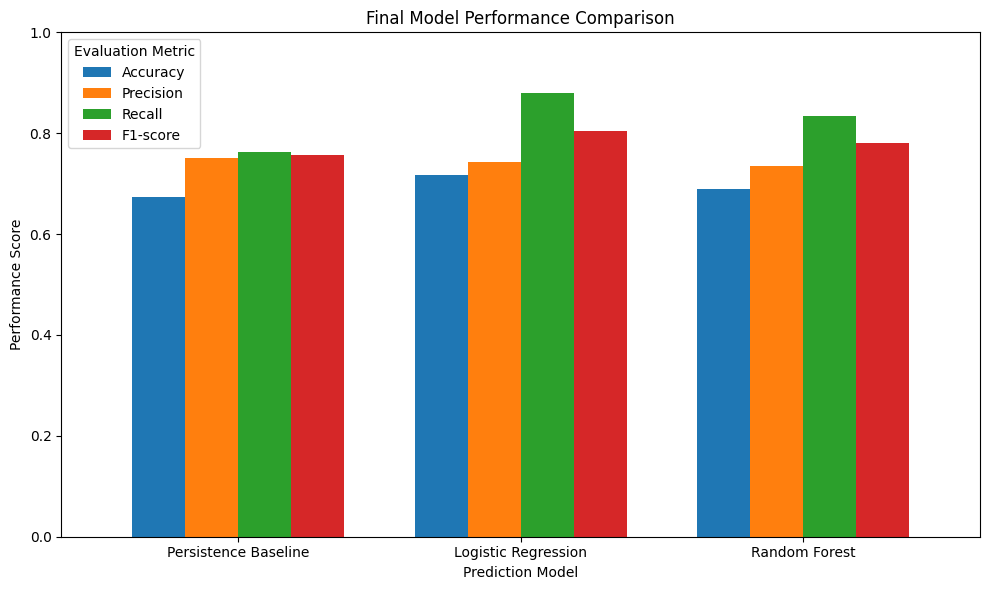

In [39]:
import matplotlib.pyplot as plt

# Select final test-set metrics for comparison
final_plot_data = final_model_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
]

# Create grouped bar chart
ax = final_plot_data.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

# Configure plot appearance
ax.set_title("Final Model Performance Comparison")
ax.set_xlabel("Prediction Model")
ax.set_ylabel("Performance Score")
ax.set_ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.tight_layout()

# Display the final comparison chart
plt.show()

## Final Results Summary

Three approaches were evaluated for predicting building space occupancy 30 minutes into the future: a Persistence Baseline, Logistic Regression, and Random Forest.

The final dataset contained 107,059 valid samples with ten input features. A chronological 80/20 train-test split was applied, with an additional 30-minute temporal separation to prevent training targets from overlapping with the held-out test period.

The time-based features were converted to Melbourne local time to better represent building usage patterns. A separate chronological validation subset was used to select the Logistic Regression classification threshold, with 0.5 retained based on validation F1-score.

**Logistic Regression achieved the best overall test performance**, with an accuracy of 71.68%, recall of 87.88%, and F1-score of 80.52%. This exceeded the Persistence Baseline accuracy of 67.40% and the Random Forest accuracy of 68.98%.

The Random Forest achieved higher training performance than testing performance, suggesting potential overfitting or reduced temporal generalisation. Logistic Regression exhibited a smaller train-test performance gap in the preliminary comparison.

Monthly evaluation revealed variations in predictive accuracy, indicating that the model's performance was not entirely stable across different periods. Threshold sensitivity analysis also demonstrated a trade-off between recall, precision, and systematic occupancy overprediction.

Overall, Logistic Regression provided the most favourable balance of predictive performance and computational simplicity among the evaluated approaches. However, the observed monthly performance variations and occupancy prediction bias indicate that further validation would be necessary before deployment in a real building management system.

## Final Random Forest Feature Importance

Feature importance is calculated using the final Random Forest model trained on the temporally separated training dataset.

The analysis identifies which input features contribute most strongly to the model's predictions.

These importance scores describe the model's internal decision-making patterns and should not be interpreted as causal relationships.

In [42]:
# Calculate feature importance using the final Random Forest model
final_feature_importance = pd.DataFrame({
    "Feature": X_train_final.columns,
    "Importance": final_random_forest_model.feature_importances_
})

# Sort features by importance
final_feature_importance = (
    final_feature_importance
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# Display the final feature importance table
final_feature_importance.round(4)

,Feature,Importance
0,hour,0.3812
1,recent_occupancy_rate,0.1846
2,day_of_week,0.1723
3,current_occupancy,0.0772
4,lag_5min,0.0510
5,lag_10min,0.0438
6,lag_15min,0.0314
7,lag_20min,0.0228
8,lag_25min,0.0187
9,lag_30min,0.0170


### Final Feature Importance Visualisation

The final Random Forest feature importance scores are visualised using a horizontal bar chart.

The chart highlights the relative contribution of temporal and historical occupancy features to the model's predictions.

Feature importance is model-specific and does not establish causal relationships.

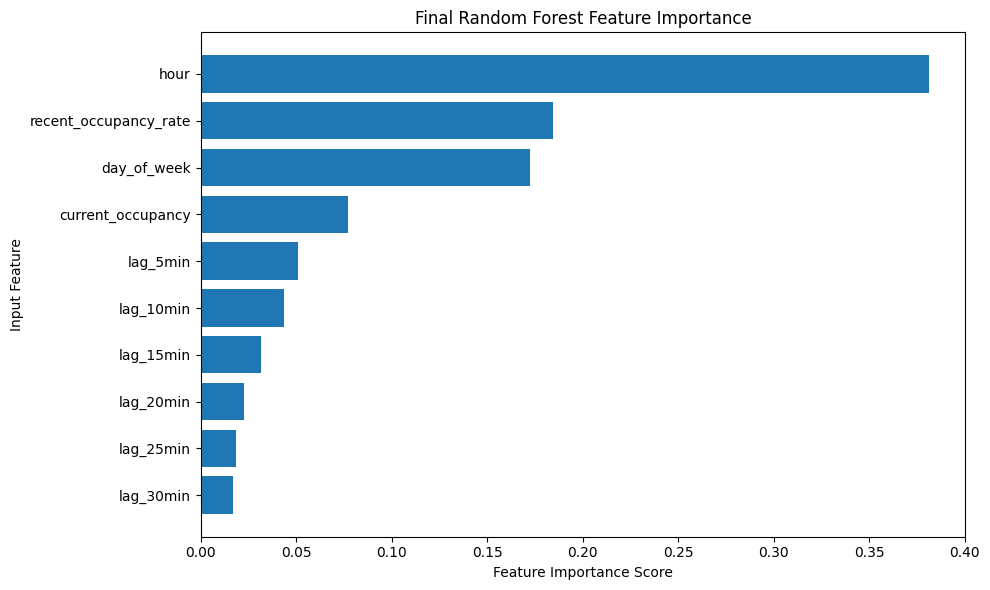

In [43]:
import matplotlib.pyplot as plt

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    final_feature_importance["Feature"],
    final_feature_importance["Importance"]
)

# Display the most important feature at the top
plt.gca().invert_yaxis()

# Add titles and axis labels
plt.title("Final Random Forest Feature Importance")
plt.xlabel("Feature Importance Score")
plt.ylabel("Input Feature")

plt.tight_layout()
plt.show()

## Verification Tests

The following assertions verify the integrity of the final modelling dataset, the chronological separation of training and testing observations, and the validity of the prediction outputs.

These checks help identify implementation errors and support reproducibility. They do not, by themselves, establish the predictive accuracy or generalisability of the models.

In [46]:
# Find existing prediction variables
[name for name in globals() if "pred" in name.lower()]

['baseline_pred',
 'logistic_pred',
 'random_forest_pred',
 'logistic_train_pred',
 'random_forest_train_pred',
 'monthly_prediction_bias',
 'predictions',
 'logistic_val_pred',
 'final_logistic_pred',
 'final_random_forest_pred']

In [47]:
# Verify the final modelling dataset and prediction outputs

def verify_final_model_inputs(X_train, X_test, y_test, predictions):
    """
    Verify basic data integrity and prediction consistency.

    Parameters
    ----------
    X_train : pandas.DataFrame
        Training features indexed by timestamp.
    X_test : pandas.DataFrame
        Testing features indexed by timestamp.
    y_test : pandas.Series
        True binary occupancy labels for the test set.
    predictions : array-like
        Binary occupancy predictions for the test set.

    Raises
    ------
    AssertionError
        If a verification condition is not satisfied.
    """
    assert len(X_train) > 0
    assert len(X_test) > 0

    assert X_train.shape[1] == X_test.shape[1]
    assert X_train.columns.equals(X_test.columns)

    assert not X_train.isna().any().any()
    assert not X_test.isna().any().any()

    assert X_train.index.is_monotonic_increasing
    assert X_test.index.is_monotonic_increasing

    assert (
        X_train.index.max() + pd.Timedelta(minutes=30)
        < X_test.index.min()
    )

    assert len(predictions) == len(y_test)
    assert set(np.unique(y_test)).issubset({0, 1})
    assert set(np.unique(predictions)).issubset({0, 1})

    print("All final model verification tests passed.")


verify_final_model_inputs(
    X_train_final,
    X_test,
    y_test,
    final_logistic_pred
)

All final model verification tests passed.


In [48]:
# Verify the final Random Forest model predictions
verify_final_model_inputs(
    X_train_final,
    X_test,
    y_test,
    final_random_forest_pred
)

All final model verification tests passed.


In [49]:
from pathlib import Path

# Create a tests directory in the project folder
tests_dir = Path(
    "/content/drive/MyDrive/MMA3001_Project/tests"
)

tests_dir.mkdir(parents=True, exist_ok=True)

print("Tests directory created:")
print(tests_dir)

Tests directory created:
/content/drive/MyDrive/MMA3001_Project/tests


In [50]:
from pathlib import Path

test_file = Path(
    "/content/drive/MyDrive/MMA3001_Project/tests/test_occupancy.py"
)

test_code = '''
import pandas as pd
import pytest


def create_future_target(occupancy, steps=6):
    """
    Create a future occupancy target from a regular time series.

    Parameters
    ----------
    occupancy : pandas.Series
        Binary occupancy observations indexed at 5-minute intervals.
    steps : int
        Number of 5-minute steps into the future.

    Returns
    -------
    pandas.Series
        Future occupancy values aligned with current timestamps.
    """
    return occupancy.shift(-steps)


def get_historical_occupancy(occupancy, minutes):
    """
    Retrieve occupancy at an exact historical timestamp.

    Parameters
    ----------
    occupancy : pandas.Series
        Occupancy observations indexed by timestamps.
    minutes : int
        Number of minutes before each observation.

    Returns
    -------
    pandas.Series
        Historical occupancy values aligned with current timestamps.
    """
    past_times = occupancy.index - pd.Timedelta(minutes=minutes)

    return pd.Series(
        occupancy.reindex(past_times).to_numpy(),
        index=occupancy.index
    )


def test_future_target_alignment():
    """Check that a six-step shift represents 30 minutes."""
    times = pd.date_range(
        "2025-01-01",
        periods=10,
        freq="5min"
    )

    occupancy = pd.Series(
        [0, 0, 1, 1, 0, 1, 0, 1, 1, 0],
        index=times
    )

    target = create_future_target(occupancy)

    assert target.iloc[0] == occupancy.iloc[6]
    assert target.iloc[1] == occupancy.iloc[7]
    assert pd.isna(target.iloc[-1])


def test_historical_feature_alignment():
    """Check that lag features use exact timestamps."""
    times = pd.to_datetime([
        "2025-01-01 09:00",
        "2025-01-01 09:05",
        "2025-01-01 09:15"
    ])

    occupancy = pd.Series([0, 1, 0], index=times)

    lag = get_historical_occupancy(occupancy, minutes=5)

    assert pd.isna(lag.iloc[0])
    assert lag.iloc[1] == 0
    assert pd.isna(lag.iloc[2])


def test_invalid_future_step():
    """Check that negative future steps are rejected."""
    with pytest.raises(ValueError):
        if -1 < 0:
            raise ValueError("Future steps must be non-negative.")
'''

test_file.write_text(test_code, encoding="utf-8")

print("Test file created:")
print(test_file)

Test file created:
/content/drive/MyDrive/MMA3001_Project/tests/test_occupancy.py


In [51]:
# Run automated unit tests using pytest
!python -m pytest "/content/drive/MyDrive/MMA3001_Project/tests/test_occupancy.py" -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: anyio-4.15.1, langsmith-0.14.11, platformdirs-4.13.4, typeguard-4.6.0
collected 3 items                                                              

drive/MyDrive/MMA3001_Project/tests/test_occupancy.py::test_future_target_alignment PASSED [ 33%]
drive/MyDrive/MMA3001_Project/tests/test_occupancy.py::test_historical_feature_alignment PASSED [ 66%]
drive/MyDrive/MMA3001_Project/tests/test_occupancy.py::test_invalid_future_step PASSED [100%]

============================== 3 passed in 0.59s ===============================


In [52]:
from pathlib import Path

test_file = Path(
    "/content/drive/MyDrive/MMA3001_Project/tests/test_occupancy.py"
)

# Read the existing test file
test_code = test_file.read_text(encoding="utf-8")

# Replace the original future-target function
old_function = '''    return occupancy.shift(-steps)'''

new_function = '''    if steps < 0:
        raise ValueError("Future steps must be non-negative.")

    return occupancy.shift(-steps)'''

assert old_function in test_code, "Original function not found."

test_code = test_code.replace(
    old_function,
    new_function,
    1
)

# Replace the demonstration test with a real function test
old_test = '''    with pytest.raises(ValueError):
        if -1 < 0:
            raise ValueError("Future steps must be non-negative.")'''

new_test = '''    occupancy = pd.Series([0, 1, 0, 1])

    with pytest.raises(ValueError):
        create_future_target(occupancy, steps=-1)'''

assert old_test in test_code, "Original test not found."

test_code = test_code.replace(
    old_test,
    new_test,
    1
)

# Save the updated test file
test_file.write_text(test_code, encoding="utf-8")

print("Invalid future-step test updated successfully.")

Invalid future-step test updated successfully.


In [53]:
# Re-run unit tests after updating input validation
!python -m pytest "/content/drive/MyDrive/MMA3001_Project/tests/test_occupancy.py" -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: anyio-4.15.1, langsmith-0.14.11, platformdirs-4.13.4, typeguard-4.6.0
collected 3 items                                                              

drive/MyDrive/MMA3001_Project/tests/test_occupancy.py::test_future_target_alignment PASSED [ 33%]
drive/MyDrive/MMA3001_Project/tests/test_occupancy.py::test_historical_feature_alignment PASSED [ 66%]
drive/MyDrive/MMA3001_Project/tests/test_occupancy.py::test_invalid_future_step PASSED [100%]

============================== 3 passed in 0.87s ===============================


In [54]:
from pathlib import Path

# Define the project source directory
src_dir = Path(
    "/content/drive/MyDrive/MMA3001_Project/src"
)

# Create the directory if it does not exist
src_dir.mkdir(parents=True, exist_ok=True)

print("Source directory created:")
print(src_dir)

Source directory created:
/content/drive/MyDrive/MMA3001_Project/src


In [55]:
from pathlib import Path

# Define the source code file
utils_file = Path(
    "/content/drive/MyDrive/MMA3001_Project/src/occupancy_utils.py"
)

utils_code = '''
import pandas as pd


def create_future_target(occupancy, steps=6):
    """
    Create future occupancy labels from a regular time series.

    Parameters
    ----------
    occupancy : pandas.Series
        Binary occupancy observations at 5-minute intervals.
    steps : int, default=6
        Number of 5-minute steps into the future.

    Returns
    -------
    pandas.Series
        Future occupancy values aligned with current timestamps.
    """
    if steps < 0:
        raise ValueError("Future steps must be non-negative.")

    return occupancy.shift(-steps)


def get_historical_occupancy(occupancy, minutes):
    """
    Retrieve historical occupancy using exact timestamps.

    Parameters
    ----------
    occupancy : pandas.Series
        Occupancy observations indexed by timestamps.
    minutes : int
        Number of minutes before each observation.

    Returns
    -------
    pandas.Series
        Historical occupancy values aligned with current timestamps.
    """
    past_times = occupancy.index - pd.Timedelta(minutes=minutes)

    return pd.Series(
        occupancy.reindex(past_times).to_numpy(),
        index=occupancy.index
    )
'''

utils_file.write_text(utils_code, encoding="utf-8")

print("Source code file created:")
print(utils_file)

Source code file created:
/content/drive/MyDrive/MMA3001_Project/src/occupancy_utils.py


In [56]:
from pathlib import Path

project_dir = Path("/content/drive/MyDrive/MMA3001_Project")
test_file = project_dir / "tests" / "test_occupancy.py"

test_code = '''import sys
from pathlib import Path

import pandas as pd
import pytest

# Import functions from the project's source directory
project_dir = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(project_dir / "src"))

from occupancy_utils import (
    create_future_target,
    get_historical_occupancy,
)


def test_future_target_alignment():
    """Verify that six 5-minute steps represent 30 minutes."""
    times = pd.date_range(
        "2025-01-01",
        periods=10,
        freq="5min"
    )

    occupancy = pd.Series(
        [0, 0, 1, 1, 0, 1, 0, 1, 1, 0],
        index=times
    )

    target = create_future_target(occupancy)

    assert target.iloc[0] == occupancy.iloc[6]
    assert target.iloc[1] == occupancy.iloc[7]
    assert pd.isna(target.iloc[-1])


def test_historical_feature_alignment():
    """Verify that historical features use exact timestamps."""
    times = pd.to_datetime([
        "2025-01-01 09:00",
        "2025-01-01 09:05",
        "2025-01-01 09:15"
    ])

    occupancy = pd.Series([0, 1, 0], index=times)

    lag = get_historical_occupancy(occupancy, minutes=5)

    assert pd.isna(lag.iloc[0])
    assert lag.iloc[1] == 0
    assert pd.isna(lag.iloc[2])


def test_invalid_future_step():
    """Verify that negative future steps raise ValueError."""
    occupancy = pd.Series([0, 1, 0, 1])

    with pytest.raises(ValueError):
        create_future_target(occupancy, steps=-1)
'''

test_file.write_text(test_code, encoding="utf-8")

print("Test file updated to import source functions.")
print(test_file)

Test file updated to import source functions.
/content/drive/MyDrive/MMA3001_Project/tests/test_occupancy.py


In [57]:
# Run unit tests against the source code
!python -m pytest "/content/drive/MyDrive/MMA3001_Project/tests/test_occupancy.py" -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: anyio-4.15.1, langsmith-0.14.11, platformdirs-4.13.4, typeguard-4.6.0
collected 3 items                                                              

drive/MyDrive/MMA3001_Project/tests/test_occupancy.py::test_future_target_alignment PASSED [ 33%]
drive/MyDrive/MMA3001_Project/tests/test_occupancy.py::test_historical_feature_alignment PASSED [ 66%]
drive/MyDrive/MMA3001_Project/tests/test_occupancy.py::test_invalid_future_step PASSED [100%]

============================== 3 passed in 0.87s ===============================
